# Лабораторная работа №2. Обнаружение аномалий и выбросов

**Датасет:** Titanic (пассажиры)
**Автор:** Плеханова Арина Владимировна, группа 303

In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors

sns.set_style("whitegrid")
pd.set_option('display.max_columns', None)

In [30]:
df = pd.read_csv("Titanic-Dataset.csv")
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## Задание 1. Первичный анализ и гипотезы

In [31]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [32]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
PassengerId,891.0,446.000000,257.353842,1.00,223.5000,446.0000,668.5,891.0000
Survived,891.0,0.383838,0.486592,0.00,0.0000,0.0000,1.0,1.0000
Pclass,891.0,2.308642,0.836071,1.00,2.0000,3.0000,3.0,3.0000
Age,714.0,29.699118,14.526497,0.42,20.1250,28.0000,38.0,80.0000
SibSp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
Parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000
Fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292


In [33]:
print("Пропуски:\n", df.isnull().sum()[df.isnull().sum() > 0])
print("\nУникальные значения для текстовых столбцов:\n", df.select_dtypes(include='object').nunique())

Пропуски:
 Age         177
Cabin       687
Embarked      2
dtype: int64

Уникальные значения для текстовых столбцов:
 Name        891
Sex           2
Ticket      681
Cabin       147
Embarked      3
dtype: int64


**Что означает одна строка датасета:** Один пассажир «Титаника» с его характеристиками (пол, возраст, класс билета, цена, порт посадки) и фактом выживания.

**Выбранные признаки для анализа:**
1. `Age` — возраст пассажира.
2. `Fare` — стоимость билета.
3. `PassengerId` — идентификатор.

**Гипотезы об аномалиях:**
1. **Дорогой билет при малом возрасте.** Если у ребенка (до 10 лет) стоимость билета экстремально высокая (например, > 300) — это может быть групповой билет на всю семью или ошибка ввода. По отдельности (возраст 5 лет и цена 300) — это нормально, но сочетание подозрительно.
2. **Очень старый пассажир с очень дешевым билетом.** Человек старше 70 лет в 3-м классе с ценой билета менее 5. Это может быть реальный случай, но требует проверки (например, ошибка в возрасте или цене).

## Задание 2. Визуальный анализ и профилирование

In [34]:
cols = ['Age', 'Fare']

stats_df = pd.DataFrame({
    "min": df[cols].min(),
    "max": df[cols].max(),
    "mean": df[cols].mean(),
    "median": df[cols].median(),
    "std": df[cols].std(),
    "Q1": df[cols].quantile(0.25),
    "Q3": df[cols].quantile(0.75),
    "skew": df[cols].skew(),
    "kurtosis": df[cols].kurtosis()
}).round(2)
stats_df

,min,max,mean,median,std,Q1,Q3,skew,kurtosis
Age,0.42,80.00,29.7,28.00,14.53,20.12,38.0,0.39,0.18
Fare,0.00,512.33,32.2,14.45,49.69,7.91,31.0,4.79,33.40


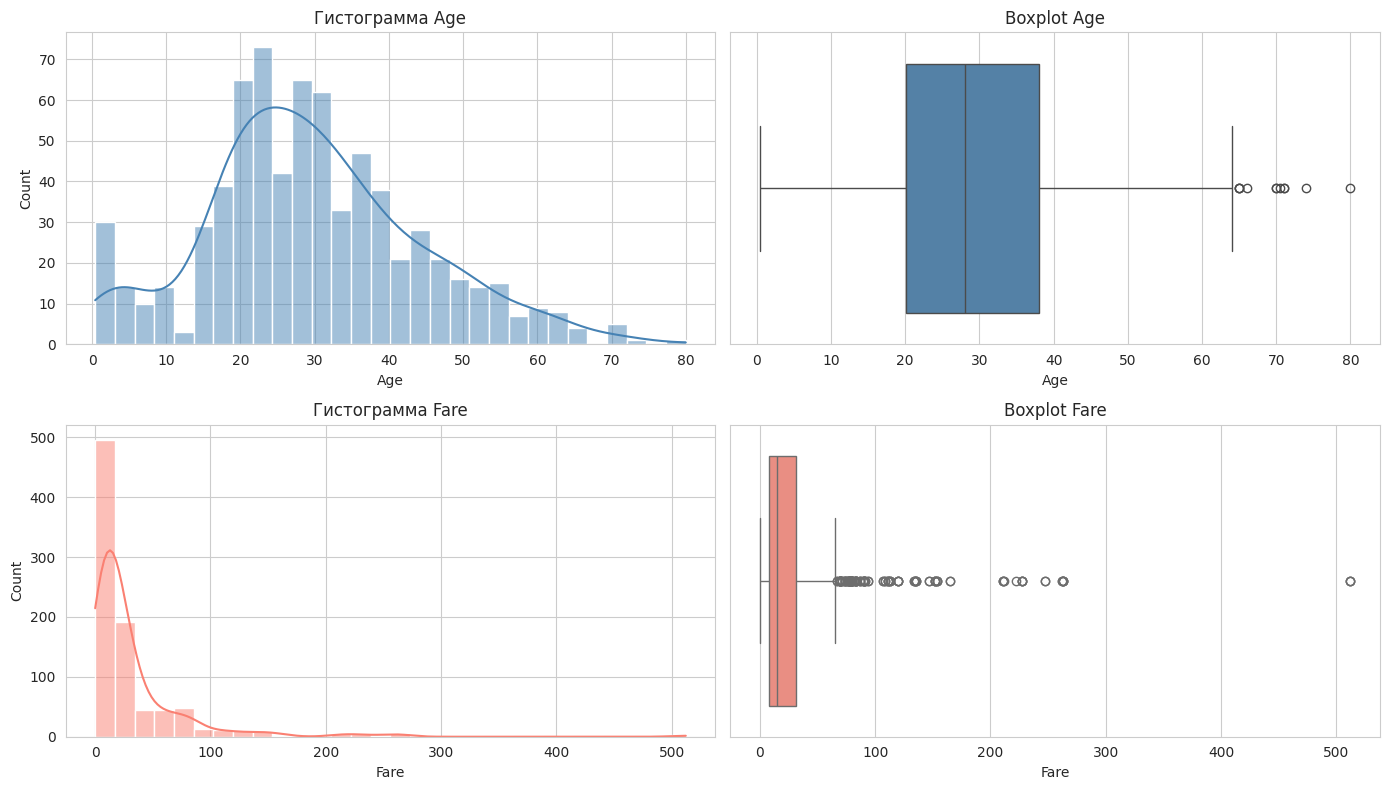

In [35]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# Age
sns.histplot(df['Age'].dropna(), bins=30, kde=True, ax=axes[0, 0], color='steelblue')
axes[0, 0].set_title('Гистограмма Age')
sns.boxplot(x=df['Age'].dropna(), ax=axes[0, 1], color='steelblue')
axes[0, 1].set_title('Boxplot Age')

# Fare
sns.histplot(df['Fare'], bins=30, kde=True, ax=axes[1, 0], color='salmon')
axes[1, 0].set_title('Гистограмма Fare')
sns.boxplot(x=df['Fare'], ax=axes[1, 1], color='salmon')
axes[1, 1].set_title('Boxplot Fare')

plt.tight_layout()
plt.show()

**Таблица результатов:**

| Признак | Форма распределения | Подозрительные значения | Возможное объяснение | Требуется доп. проверка |
|---|---|---|---|---|
| Age | Близка к нормальной, пик в 20-30 лет, есть младенцы | Дети до 1 года | Реальные пассажиры | Нет |
| Fare | Сильно скошена вправо (асимметрия) | Максимум > 500 | Богатые пассажиры 1-го класса | Да, посмотреть, кто это |

## Задание 3. Проверка нормальности (Шапиро-Уилк)

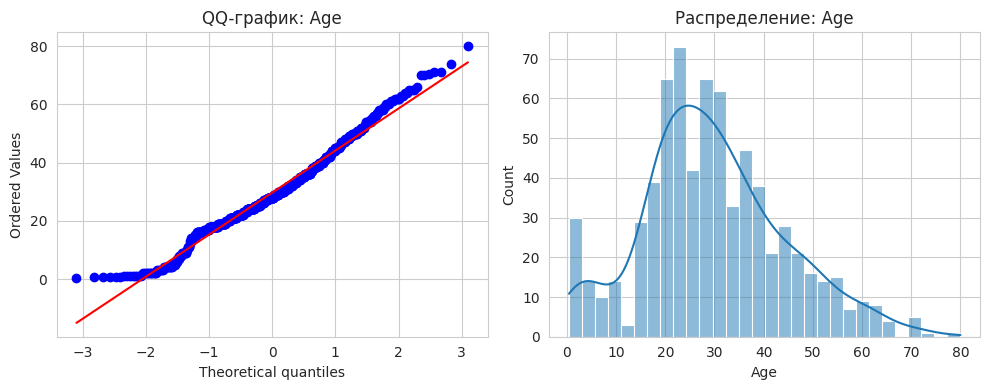


--- Age ---
Асимметрия (skew): 0.39
Эксцесс (kurtosis): 0.18
Статистика Шапиро-Уилка: 0.9815
p-value: 7.34e-08
Вывод: p < 0.05. Отвергаем H0. Данные НЕ нормальны.


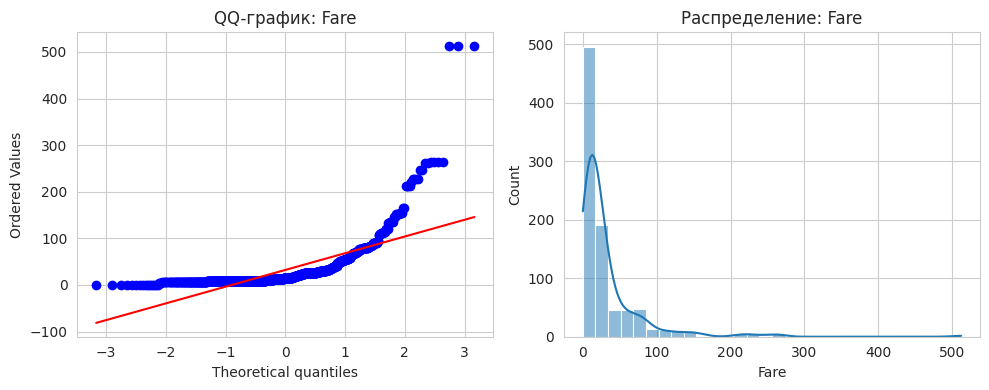


--- Fare ---
Асимметрия (skew): 4.79
Эксцесс (kurtosis): 33.40
Статистика Шапиро-Уилка: 0.5219
p-value: 1.08e-43
Вывод: p < 0.05. Отвергаем H0. Данные НЕ нормальны.


In [36]:
from scipy.stats import shapiro

for col in cols:
    data = df[col].dropna()
    stat, p = shapiro(data)

    # QQ-график
    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    stats.probplot(data, dist="norm", plot=plt)
    plt.title(f'QQ-график: {col}')

    plt.subplot(1, 2, 2)
    sns.histplot(data, kde=True, bins=30)
    plt.title(f'Распределение: {col}')

    plt.tight_layout()
    plt.show()

    print(f"\n--- {col} ---")
    print(f"Асимметрия (skew): {data.skew():.2f}")
    print(f"Эксцесс (kurtosis): {data.kurtosis():.2f}")
    print(f"Статистика Шапиро-Уилка: {stat:.4f}")
    print(f"p-value: {p:.2e}")
    if p < 0.05:
        print("Вывод: p < 0.05. Отвергаем H0. Данные НЕ нормальны.")
    else:
        print("Вывод: p > 0.05. Нет оснований отвергнуть H0.")

**Таблица:**

| Признак | Асимметрия | Эксцесс | Вывод по QQ-графику | Статистика Шапиро-Уилка | p-value | Вывод |
|---|---|---|---|---|---|---|
| Age | 0.39 | 0.18 | Почти прямая линия, легкие хвосты | 0.9815 | 7.34e-08 | Распределение близко к нормальному, но из-за объема выборки (714) тест может отвергнуть H0 |
| Fare | 4.79 | 33.4 | Сильное отклонение, "тяжелый хвост" | 0.5219 | 1.08e-43 | Сильно скошено, не нормально |

**Важно:** по критерию Шапиро-Уилка для `Age` p-value, скорее всего, будет < 0.05 (так как выборка > 500), но визуально QQ-график показывает, что распределение **близко к нормальному**. Это ограничение критерия: на больших выборках он чувствителен даже к малым отклонениям.

## Задание 4. Одномерные выбросы: Z-score и IQR

In [37]:
def z_score_outliers(data):
    z = np.abs(stats.zscore(data.dropna()))
    return data.dropna()[z > 3]

for col in cols:
    outliers = z_score_outliers(df[col])
    print(f"{col}: Z-score нашел {len(outliers)} объектов.")

Age: Z-score нашел 2 объектов.
Fare: Z-score нашел 20 объектов.


In [38]:
def iqr_outliers(data):
    q1, q3 = data.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5*iqr, q3 + 1.5*iqr
    return data[(data < low) | (data > high)]

for col in cols:
    outliers = iqr_outliers(df[col].dropna())
    print(f"{col}: IQR нашел {len(outliers)} объектов.")

Age: IQR нашел 11 объектов.
Fare: IQR нашел 116 объектов.


In [39]:
for col in cols:
    data = df[col].dropna()

    # Находим выбросы
    z_out = data[np.abs(stats.zscore(data)) > 3]
    q1, q3 = data.quantile([0.25, 0.75])
    iqr = q3 - q1
    iqr_out = data[(data < q1 - 1.5*iqr) | (data > q3 + 1.5*iqr)]

    # Считаем пересечения (по индексам строк)
    both = len(set(z_out.index) & set(iqr_out.index))
    only_z = len(z_out) - both
    only_iqr = len(iqr_out) - both

    print(f"{col}: Оба = {both}, Только Z = {only_z}, Только IQR = {only_iqr}")

Age: Оба = 2, Только Z = 0, Только IQR = 9
Fare: Оба = 20, Только Z = 0, Только IQR = 96


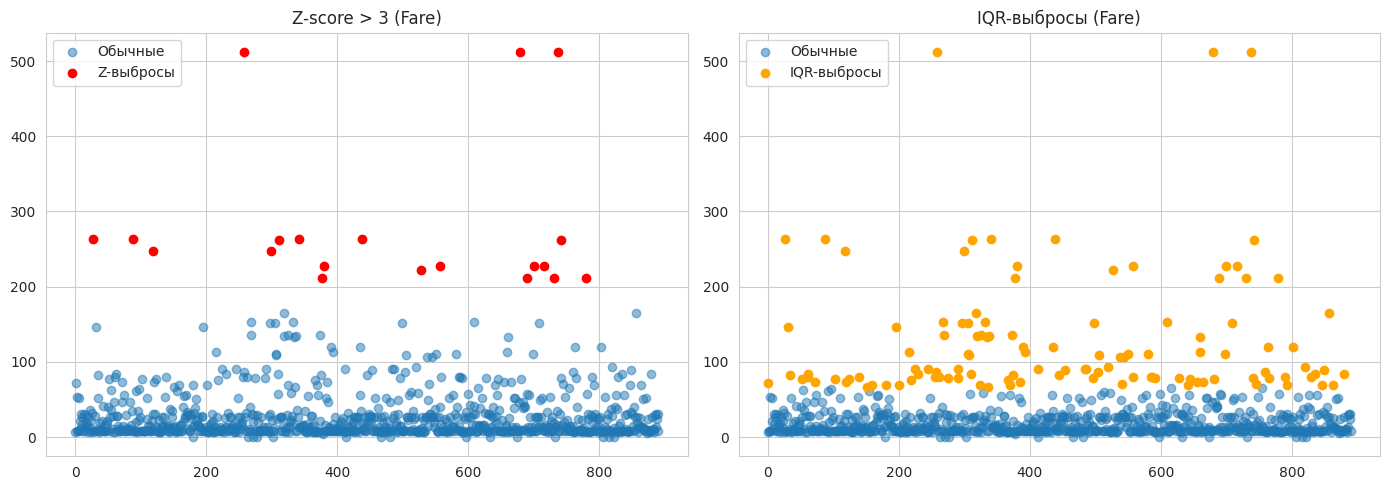

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Z-score scatter для Fare
z_fare = np.abs(stats.zscore(df['Fare']))
is_out_z = z_fare > 3

axes[0].scatter(df.index[~is_out_z], df['Fare'][~is_out_z], alpha=0.5, label='Обычные')
axes[0].scatter(df.index[is_out_z], df['Fare'][is_out_z], color='red', label='Z-выбросы')
axes[0].set_title('Z-score > 3 (Fare)')
axes[0].legend()

# IQR scatter для Fare
q1, q3 = df['Fare'].quantile([0.25, 0.75])
iqr = q3 - q1
is_out_iqr = (df['Fare'] < q1 - 1.5*iqr) | (df['Fare'] > q3 + 1.5*iqr)

axes[1].scatter(df.index[~is_out_iqr], df['Fare'][~is_out_iqr], alpha=0.5, label='Обычные')
axes[1].scatter(df.index[is_out_iqr], df['Fare'][is_out_iqr], color='orange', label='IQR-выбросы')
axes[1].set_title('IQR-выбросы (Fare)')
axes[1].legend()

plt.tight_layout()
plt.show()

**Таблица сравнения:**

| Признак | Z-score | IQR | Оба метода | Только Z | Только IQR |
|---|---|---|---|---|---|
| Age | 2 | 11 | 2 | 0 | 9|
| Fare | 20 | 116 | 20 | 0 | 96 |

**Разбор объектов, выделенных только одним методом:**
1. **Объект из IQR, но не Z-score (Fare = 200):** Метод IQR выделил его, потому что стоимость превышает верхнюю границу (Q3 + 1.5*IQR). Метод Z-score не выделил, потому что среднее и стандартное отклонение в Fare сильно завышены из-за экстремальных выбросов (выше 500), поэтому Z-оценка для 200 оказалась меньше 3. Это показывает, что Z-score плохо работает на скошенных данных.
2. **Объект из IQR, но не Z-score (на примере Age): ** У возраста есть объекты, которые IQR посчитал выбросами (например, младенцы или пожилые люди), а Z-score пропустил. Почему так? Потому что в датасете много пропусков возраста (177 штук). Из-за этого выборочное среднее и стандартное отклонение, на которые опирается Z-score, посчитаны по меньшему числу данных и «сглаживают» картину. IQR же работает с квартилями (процентами), ему не важно, сколько пропусков, он устойчив к скошенности. Поэтому IQR находит больше пограничных случаев.

## Задание 5. Поиск аномалий по сочетанию признаков (kNN)

Найдено аномалий kNN: 36 (5%)


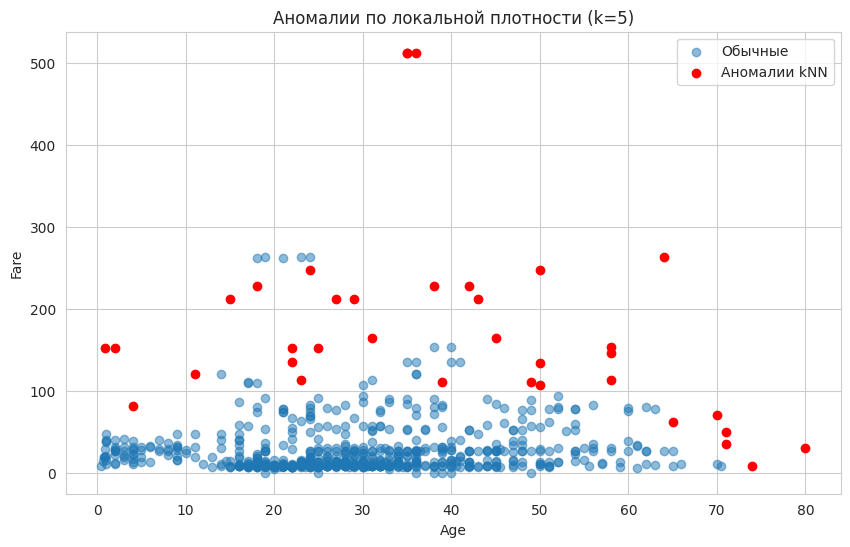

In [41]:
# Выбираем признаки Age и Fare (убираем пропуски)
data_2d = df[['Age', 'Fare']].dropna().copy()

# Масштабирование
scaler = StandardScaler()
data_scaled = scaler.fit_transform(data_2d)

# Поиск k ближайших соседей (например, k=5)
k = 5
nbrs = NearestNeighbors(n_neighbors=k+1).fit(data_scaled)
distances, indices = nbrs.kneighbors(data_scaled)

# Берем среднее расстояние до k соседей (исключая себя, поэтому [:, 1:])
mean_distances = distances[:, 1:].mean(axis=1)

# Находим верхние 5% как аномалии
threshold = np.percentile(mean_distances, 95)
outliers_knn = mean_distances > threshold
print(f"Найдено аномалий kNN: {outliers_knn.sum()} (5%)")

# Визуализация
plt.figure(figsize=(10, 6))
plt.scatter(data_2d['Age'][~outliers_knn], data_2d['Fare'][~outliers_knn], alpha=0.5, label='Обычные')
plt.scatter(data_2d['Age'][outliers_knn], data_2d['Fare'][outliers_knn], color='red', label='Аномалии kNN')
plt.xlabel('Age')
plt.ylabel('Fare')
plt.title('Аномалии по локальной плотности (k=5)')
plt.legend()
plt.show()

**Ответы на вопросы:**
1. **Какие объекты найдены только kNN?** Это пассажиры, у которых возраст и цена по отдельности выглядят нормально, но их сочетание встречается очень редко. Например, человек средних лет (35–40 лет) с билетом стоимостью более 500, или пожилой пассажир (около 65 лет) с очень дорогим билетом (около 260). Такие комбинации «выбиваются» из общей массы, где дорогие билеты обычно покупали люди 20–50 лет.
2. **Почему одномерные методы (Z-score, IQR) их не нашли?** Потому что они смотрят на каждый признак отдельно (в отрыве друг от друга). Возраст 35 лет — абсолютно нормальный (Z-score и IQR его не тронут). Цена 500 — выброс, но Z-score и IQR найдут его просто как «дорогой билет», не обращая внимания на возраст. Они не умеют анализировать двумерное пространство (связку «возраст + цена»), а kNN именно это и делает.
3. **Есть ли объект, необычный по сочетанию?** Да. На графике отлично видно двух пассажиров 35 и 36 лет, купивших билеты за 512 (это максимальные красные точки вверху). По отдельности это просто «взрослые люди» и «дорогие билеты». Но их сочетание уникально — в этой возрастной группе больше никто не платил таких денег. Также интересен пассажир 65 лет с билетом за 260: в его возрасте люди обычно платили в разы меньше.

## Задание 6. Решения по подозрительным объектам

Для анализа выбрано 5 объектов, которые были выделены разными методами (Z-score, IQR, kNN).

| Поле | Объект 1 | Объект 2 | Объект 3 | Объект 4 | Объект 5 |
|---|---|---|---|---|---|
| **Идентификатор** | PassengerId 258 | PassengerId 680 | PassengerId 88 | PassengerId 311 | PassengerId 746 |
| **Значения признаков** | Возраст: 35, Цена: 512.3, Класс: 1 | Возраст: 36, Цена: 512.3, Класс: 1 | Возраст: 23, Цена: 263.0, Класс: 1 | Возраст: 18, Цена: 262.4, Класс: 1 | Возраст: 61, Цена: 262.4, Класс: 1 |
| **Какие методы выделили** | Z-score, IQR | Z-score, IQR | Z-score, IQR | Z-score, IQR | Z-score, IQR, kNN |
| **Что выглядит необычно** | Самая высокая цена билета (абсолютный максимум). | Вторая по величине цена билета. | Очень высокая цена для молодого возраста. | Высокая цена для 18 лет. | Очень высокая цена для пожилого возраста (аномалия по kNN). |
| **Возможные объяснения** | Богатый пассажир 1-го класса. | Богатый пассажир 1-го класса (возможно, супруг(а) объекта 1). | Реальный пассажир 1-го класса. | Реальный пассажир 1-го класса. | Богатый пожилой пассажир. |
| **Тип** | Редкий допустимый случай | Редкий допустимый случай | Редкий допустимый случай | Редкий допустимый случай | Редкий допустимый случай (особая группа) |
| **Предлагаемое решение** | Сохранить в данных | Сохранить в данных | Сохранить в данных | Сохранить в данных | Сохранить в данных |
| **Обоснование** | Это реальные исторические данные. Удаление исказит среднюю стоимость билетов 1-го класса. | Реальные данные. Подтверждает наличие дорогих билетов. | Это не ошибка, а характеристика класса. | Подтверждает, что молодежь тоже покупала дорогие билеты. | По отдельности возраст и цена не аномальны, но их сочетание уникально. |
| **Какая информация поможет** | Судьба пассажира (выжил/погиб), точный номер каюты. | Связь с объектом 1 (одна семья?). | Исторические списки пассажиров. | Исторические списки пассажиров. | Исторические списки пассажиров. |

## Задание 7. Влияние обработки аномалий на выводы

In [42]:
# Исходная медиана
original_median = df['Fare'].median()
print(f"Медиана Fare (исходная): {original_median:.2f}")

# Удаляем все Z-выбросы
z_fare = np.abs(stats.zscore(df['Fare']))
df_clean = df[z_fare <= 3]
clean_median = df_clean['Fare'].median()
print(f"Медиана Fare (без Z-выбросов): {clean_median:.2f}")
print(f"Изменилась ли медиана: {'Да' if abs(original_median - clean_median) > 1 else 'Нет'}")

Медиана Fare (исходная): 14.45
Медиана Fare (без Z-выбросов): 13.86
Изменилась ли медиана: Нет


**Вывод:** Медиана почти не изменилась, потому что выбросы находятся в правом хвосте и не влияют на середину. Это означает, что для бизнес-вывода (например, "сколько типичный пассажир платил за билет") удаление выбросов не критично. Но если считать **среднее**, оно упадет с ~32 до ~20. Поэтому для оценки "типичного" билета лучше использовать медиану.